# Why AI servers at factories need less new grid capacity: a toy example

This notebook shows the mechanism of the paper *Coordinating Distributed AI Servers with Industrial Loads to Reduce Grid-Interconnection Needs* on a small, **stylized** case. The numbers are made up to make the effect easy to see; they are not results of the paper.

A factory's grid connection is sized for its production peak, so outside that peak part of the connection is unused. AI servers placed at the factory can use this headroom, and flexible AI tasks can be scheduled away from the production peak. If the group has several factories whose peaks occur at different times, tasks can also be routed to whichever factory has headroom. Each of these steps reduces the **additional grid-interconnection capacity**, that is, how much the site's peak grid demand rises above its pre-AI peak.

The model is the paper's eq. (1a)–(1i), simplified to one hardware type and solved with the open-source HiGHS solver. The code is in [`mechanism_demo.py`](mechanism_demo.py).

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import matplotlib.pyplot as plt
import pandas as pd
import mechanism_demo as demo

pd.options.display.float_format = "{:.2f}".format
COLORS = {"production": "#9e9e9e", "ai": "#e8833a", "excess": "#d62728", "peak": "black"}

## 1. The toy corporate group

Three factories of the same size, A, B and C, each with a production peak of a few hours, eight hours apart. The group's AI demand peaks at 14:00. One third of it is **firm** (served in the hour it arrives); two thirds are **flexible** and may be delayed by up to 12 hours. AI demand is given in MW of server power at full load; facility power adds 30% for cooling and power delivery.

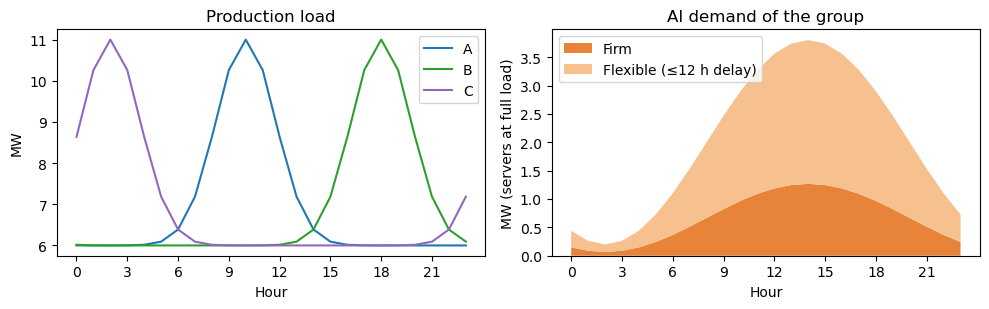

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharex=True)
demo.PRODUCTION_LOAD.plot(ax=axes[0], color=["#1f77b4", "#2ca02c", "#9467bd"])
axes[0].set(title="Production load", xlabel="Hour", ylabel="MW")
axes[1].stackplot(demo.HOURS, demo.FIRM_DEMAND, demo.FLEX_ARRIVALS,
                  labels=["Firm", "Flexible (≤12 h delay)"], colors=["#e8833a", "#f6c08f"])
axes[1].set(title="AI demand of the group", xlabel="Hour", ylabel="MW (servers at full load)")
axes[1].legend(loc="upper left")
for ax in axes:
    ax.set_xticks(range(0, 24, 3))
plt.tight_layout()

## 2. The model in brief

For each case the group chooses how many servers to install at each host site and when (and where) to run each task, minimizing annual cost:

| Paper | In this notebook |
|---|---|
| (1a) objective | server cost + demand charge on additional capacity + energy cost at hourly prices (400–700 CNY/MWh, highest at 14:00) |
| (1b) firm demand | served in its arrival hour |
| (1c) flexible demand | each hourly job served within 12 h of its arrival |
| (1d) fixed shares | without routing, each site serves a fixed one-third of every task |
| (1e)–(1f) servers | compute ≤ online servers ≤ installed servers |
| (1g) AI load | facility power = 1.3 × (standby + idle + load-dependent power) |
| (1h) connection | production load + AI load ≤ pre-AI peak + additional capacity |
| (1i) planning margin | installed servers ≥ 1.15 × average compute |

Servers are expensive compared with the demand charge (as in the paper), so the model first avoids idle servers and then uses the remaining freedom to stay within the existing connection.

## 3. Six cases, one mechanism at a time

Cases 1–4 cross two choices, as in Section IV-B of the paper: where the servers are (a new data center without production load, or host factory A) and whether flexible tasks may be shifted. Cases 5–6 spread the servers over all three factories, without and with routing.

In [3]:
table, results = demo.run_all()
table

,case,additional_capacity_mw,installed_servers_mw,annual_cost_million_cny
0,"1 New data center, no shifting",4.94,3.80,149.40
1,"2 New data center, with shifting",2.99,2.30,93.92
2,"3 Host factory, no shifting",3.79,3.80,148.90
3,"4 Host factory, with shifting",1.29,2.30,93.24
4,"5 Three sites, fixed shares",0.91,2.30,93.16
5,"6 Three sites, with routing",0.06,2.30,92.75


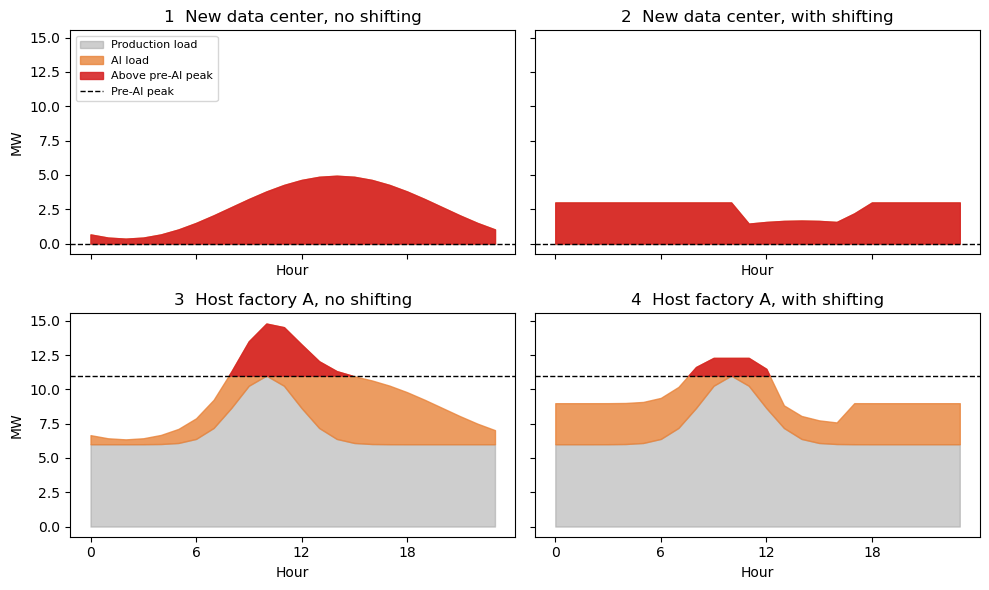

In [4]:
def plot_site(ax, result, node, title):
    L = result["production_load"][node]
    p = result["ai_load"][node]
    K = result["capacity"][node]
    ax.fill_between(demo.HOURS, 0, L, color=COLORS["production"], alpha=0.5, label="Production load")
    ax.fill_between(demo.HOURS, L, L + p, color=COLORS["ai"], alpha=0.8, label="AI load")
    ax.fill_between(demo.HOURS, K, L + p, where=(L + p) > K, color=COLORS["excess"], alpha=0.9,
                    interpolate=True, label="Above pre-AI peak")
    ax.axhline(K, color=COLORS["peak"], ls="--", lw=1, label="Pre-AI peak")
    ax.set(title=title, xlabel="Hour", xticks=range(0, 24, 6))

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharey=True, sharex=True)
plot_site(axes[0, 0], results[0], "A", "1  New data center, no shifting")
plot_site(axes[0, 1], results[1], "A", "2  New data center, with shifting")
plot_site(axes[1, 0], results[2], "A", "3  Host factory A, no shifting")
plot_site(axes[1, 1], results[3], "A", "4  Host factory A, with shifting")
for ax in axes[:, 0]:
    ax.set_ylabel("MW")
axes[0, 0].legend(loc="upper left", fontsize=8)
plt.tight_layout()

At a new data center (top row) there is no production load, so the whole AI load lies above the pre-AI peak of zero and its peak needs new capacity; shifting only lowers it by flattening the AI load. At host factory A (bottom row), the AI peak (14:00) comes after the production peak (10:00), so part of the AI load fits within the existing connection even without shifting. With shifting, flexible tasks also move out of the production peak and the expensive afternoon into the night, when factory A has headroom.

The two choices reinforce each other: co-location saves more when tasks can be shifted.

In [5]:
grid = pd.DataFrame(
    [[results[0]["additional_capacity_mw"], results[1]["additional_capacity_mw"]],
     [results[2]["additional_capacity_mw"], results[3]["additional_capacity_mw"]]],
    index=["New data center", "Host factory"], columns=["No shifting", "With shifting"])
grid.loc["Reduction by co-location"] = 1 - grid.loc["Host factory"] / grid.loc["New data center"]
grid

,No shifting,With shifting
New data center,4.94,2.99
Host factory,3.79,1.29
Reduction by co-location,0.23,0.57


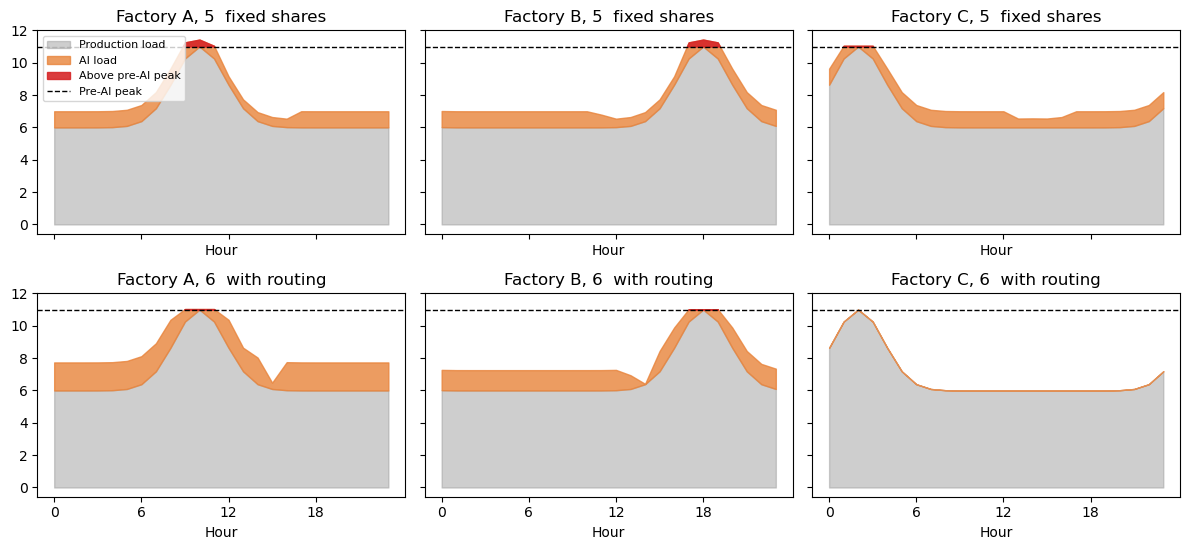

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(12, 5.6), sharey=True, sharex=True)
for row, (result, label) in enumerate([(results[4], "5  fixed shares"), (results[5], "6  with routing")]):
    for col, node in enumerate(demo.FACTORIES):
        plot_site(axes[row, col], result, node, f"Factory {node}, {label}")
axes[0, 0].legend(loc="upper left", fontsize=8)
plt.tight_layout()

**Steps 4 → 5 → 6, several sites and routing.** With servers at all three factories but a fixed one-third share each, every site still runs some work during its own production peak. With routing, each task runs at whichever factory has headroom at that hour, and the additional capacity almost disappears.

## 4. Step 7: a battery instead of new capacity

The remaining excess can also be shaved by a battery behind the meter. Following Supplementary Methods 5 of the paper, the battery power equals the additional capacity and its energy covers the daily excess (90% round-trip efficiency). It recharges in hours with headroom.

In [7]:
bat = demo.battery(results[3])
print(f"Battery at host factory A (case 4): {bat['power_mw']:.2f} MW, {bat['energy_mwh']:.1f} MWh")

Battery at host factory A (case 4): 1.29 MW, 5.3 MWh


## 5. Summary

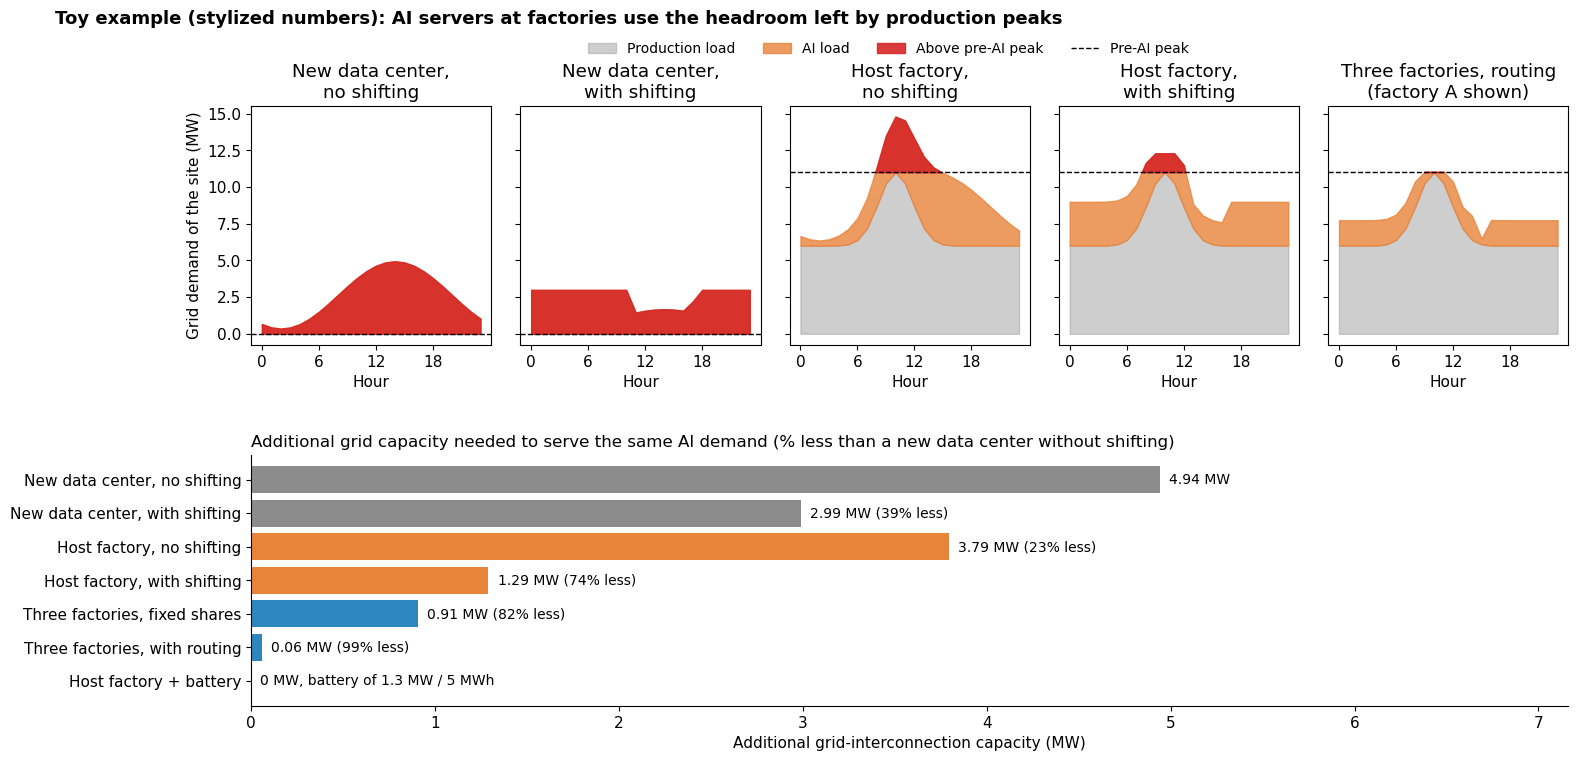

In [8]:
# The figure shown at the top of the repository README.
plt.rcParams.update({"font.size": 11})
fig = plt.figure(figsize=(17, 8))
grid = fig.add_gridspec(2, 5, height_ratios=[1, 1.05], hspace=0.45, wspace=0.12, top=0.86)
top = [fig.add_subplot(grid[0, i]) for i in range(5)]
for ax in top[1:]:
    ax.sharey(top[0])
    ax.tick_params(labelleft=False)
plot_site(top[0], results[0], "A", "New data center,\nno shifting")
plot_site(top[1], results[1], "A", "New data center,\nwith shifting")
plot_site(top[2], results[2], "A", "Host factory,\nno shifting")
plot_site(top[3], results[3], "A", "Host factory,\nwith shifting")
plot_site(top[4], results[5], "A", "Three factories, routing\n(factory A shown)")
top[0].set_ylabel("Grid demand of the site (MW)")
handles, labels_ = top[0].get_legend_handles_labels()
fig.legend(handles, labels_, loc="upper center", bbox_to_anchor=(0.5, 0.955), ncol=4, frameon=False, fontsize=10)

ax = fig.add_subplot(grid[1, :])
cases = [
    ("New data center, no shifting", results[0], "#8c8c8c"),
    ("New data center, with shifting", results[1], "#8c8c8c"),
    ("Host factory, no shifting", results[2], "#e8833a"),
    ("Host factory, with shifting", results[3], "#e8833a"),
    ("Three factories, fixed shares", results[4], "#2e86c1"),
    ("Three factories, with routing", results[5], "#2e86c1"),
]
names = [c[0] for c in cases] + ["Host factory + battery"]
values = [c[1]["additional_capacity_mw"] for c in cases] + [0.0]
colors = [c[2] for c in cases] + ["#2ca02c"]
y = range(len(names))[::-1]
bars = ax.barh(list(y), values, color=colors)
for yi, v in zip(y, values[:-1]):
    ax.text(v + 0.05, yi, f"{v:.2f} MW ({1 - v / values[0]:.0%} less)" if v < values[0] else f"{v:.2f} MW",
            va="center", fontsize=10)
ax.text(0.05, list(y)[-1], f"0 MW, battery of {bat['power_mw']:.1f} MW / {bat['energy_mwh']:.0f} MWh", va="center", fontsize=10)
ax.set_yticks(list(y), names)
ax.set_xlim(0, values[0] * 1.45)
ax.set_xlabel("Additional grid-interconnection capacity (MW)")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Additional grid capacity needed to serve the same AI demand (% less than a new data center without shifting)", loc="left", fontsize=12)
fig.suptitle("Toy example (stylized numbers): AI servers at factories use the headroom left by production peaks",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.savefig("figures/mechanism_at_a_glance.png", dpi=150, bbox_inches="tight")

In [9]:
summary = table[["case", "additional_capacity_mw"]].copy()
summary["reduction_vs_step_1"] = 1 - summary["additional_capacity_mw"] / summary["additional_capacity_mw"].iloc[0]
summary

,case,additional_capacity_mw,reduction_vs_step_1
0,"1 New data center, no shifting",4.94,0.00
1,"2 New data center, with shifting",2.99,0.39
2,"3 Host factory, no shifting",3.79,0.23
3,"4 Host factory, with shifting",1.29,0.74
4,"5 Three sites, fixed shares",0.91,0.82
5,"6 Three sites, with routing",0.06,0.99


## 6. From the toy example to the paper

The paper applies the same model to 31 manufacturing industries in China in 2030, with measured production-load profiles, six task classes, CPU and GPU servers, hourly prices and a 168-hour week. There, factory-site deployment needs about 60% less additional capacity than new large data centers, and multi-site deployment with routing about 98% less. See the main paper and [`docs/si.pdf`](../docs/si.pdf).

Limits of the toy case: one day, one hardware type, made-up loads and demand, and no network or data-residency limits on routing.